In [11]:
#data manip
import pandas as pd
import numpy as np

#data vis
import matplotlib.pyplot as plt

In [14]:
#load data 
X = pd.read_csv("mnist_training.csv", header=None)
y = pd.read_csv("mnist_train_class.csv", header=None).squeeze("columns")

#test
print("Image data",X.shape)
print("Lable data",y.shape)

Image data (60000, 784)
Lable data (60000,)


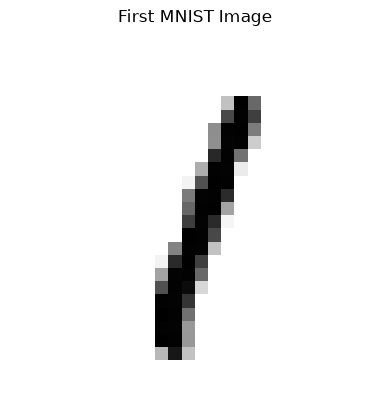

Actual digit: 1


In [25]:
# Display the first image
first_image = X.iloc[0].to_numpy().reshape(28, 28)

plt.imshow(first_image, cmap="gray")
plt.title("First MNIST Image")
plt.axis("off")
plt.show()

# Display its actual label
print("Actual digit:", y.iloc[0])

In [27]:
#normalize
X = X.astype("float32")/255.0

print("Minimum pixel value:", X.min().min())
print("Maximum pixel value:", X.max().max())

Minimum pixel value: 0.0
Maximum pixel value: 1.5378702e-05


In [28]:
#data split 
from sklearn.model_selection import train_test_split 

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#test
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (48000, 784)
Testing images: (12000, 784)


In [30]:
#polynomial SVM

from sklearn.svm import SVC

polyK  = SVC(
    kernel="poly",
    degree=3,
    C=1,
    gamma="scale",
    coef0=1
)

polyK.fit(X_train,y_train)
y_pred = polyK.predict(X_test)

In [31]:
#eval
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, average="weighted"
))

print("Recall:", recall_score(
    y_test, y_pred, average="weighted"
))

print("F1 Score:", f1_score(
    y_test, y_pred, average="weighted"
))

print(classification_report(y_test, y_pred))

Accuracy: 0.972
Precision: 0.9720269667372541
Recall: 0.972
F1 Score: 0.9719943401148495
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      1185
           1       0.98      0.99      0.98      1348
           2       0.96      0.97      0.97      1192
           3       0.97      0.97      0.97      1226
           4       0.98      0.97      0.98      1168
           5       0.96      0.97      0.96      1084
           6       0.98      0.97      0.98      1184
           7       0.97      0.97      0.97      1253
           8       0.97      0.96      0.97      1170
           9       0.97      0.96      0.96      1190

    accuracy                           0.97     12000
   macro avg       0.97      0.97      0.97     12000
weighted avg       0.97      0.97      0.97     12000



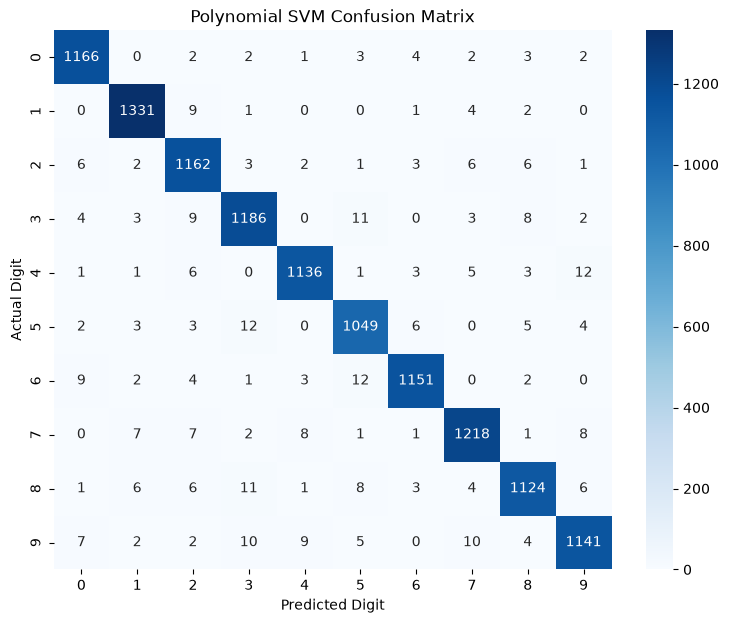

In [32]:
#confusion matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("Polynomial SVM Confusion Matrix")
plt.show()

In [33]:
#comparing degrees
degrees = [2, 3, 4]

results = []

for degree in degrees:

    model = SVC(
        kernel="poly",
        degree=degree,
        C=1,
        gamma="scale",
        coef0=1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Degree": degree,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted"
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted"
        ),
        "F1 Score": f1_score(
            y_test, predictions, average="weighted"
        )
    })

results_df = pd.DataFrame(results)

results_df

,Degree,Accuracy,Precision,Recall,F1 Score
0,2,0.966000,0.966004,0.966000,0.965986
1,3,0.972000,0.972027,0.972000,0.971994
2,4,0.974167,0.974196,0.974167,0.974164


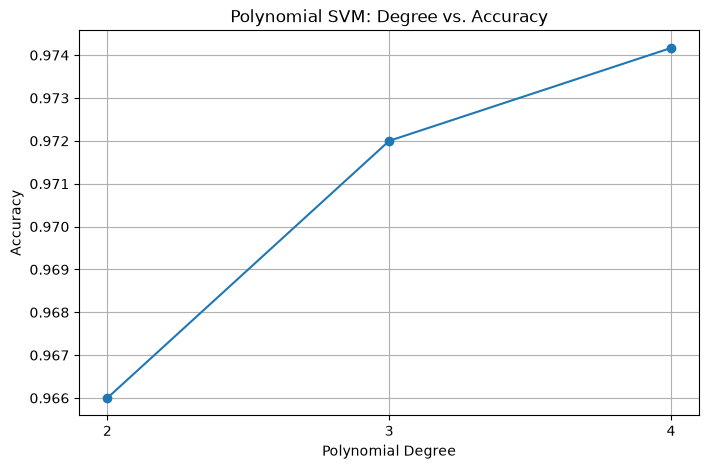

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Degree"],
    results_df["Accuracy"],
    marker="o"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Accuracy")
plt.title("Polynomial SVM: Degree vs. Accuracy")
plt.xticks(degrees)
plt.grid(True)

plt.show()